# 量子材料 · 两站点 Hubbard 能谱与双占据

QuantumBridge / 科学计算 / 中文可执行案例

**执行状态：仅本地运行；未提交夸父真机；新增云任务 0。**

面向了解 Python 的读者：完成建模、检查中间结果、运行原生电路或明确标记的经典密码步骤，并与独立基线核对。

**范围边界：** 两站点有限簇示例，没有晶体几何、周期边界、真实半导体能带、电池或催化材料数据库；不能直接输出真实材料带隙。

## 1. 原理与计算对象

采用两站点、每站点两自旋的开边界费米 Hubbard 模型：
$H=-t\sum_\sigma(a^\dagger_{0\sigma}a_{1\sigma}+h.c.)+U\sum_i n_{i\uparrow}n_{i\downarrow}$。
模式依次为 site0 up/down、site1 up/down，Jordan-Wigner 映射到四比特。在 N=1、2、3 扇区独立对角化。
半填充基态 $E_2=(U-\sqrt{U^2+16t^2})/2$，双占据 $D=(1-U/\sqrt{U^2+16t^2})/2$。有限簇电荷隙为 $E_3+E_1-2E_2$，**不是周期晶体能带隙**。

选 U/t=4 的经典精确基态，使用现有原生实幅度制备电路加载，再测量 $n_0n_1+n_2n_3$。因此本例验证的是建模、态制备和可观测量采样，不是用量子算法求出了未知基态。

## 2. 实现步骤

1. 构造跃迁与在位相互作用的费米算子，并映射原生 Pauli 哈密顿量。
2. 扫描 U/t=0,1,2,4,6,8，记录粒子数扇区能量、电荷隙与双占据。
3. 用解析公式交叉验证本地矩阵本征值。
4. 将 U/t=4 的经典基态振幅加载到四比特电路。
5. 对占据数采样并与解析双占据比较，给出标准误。

## 3. 环境与可复现参数

依赖本仓库、NumPy、Matplotlib、Jupyter；安全案例还使用已安装的 OpenSSL / cryptography。模型和电路不调用 Qiskit 或 PennyLane。Notebook 保留真实执行输出，Python 解释器版本会在下方打印。

In [1]:
import os, sys, json
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
root = next((p for p in [Path(os.environ.get("QB_REPO_ROOT", ".")).resolve(), *Path.cwd().resolve().parents] if (p/"quantumbridge").is_dir() and (p/"scripts").is_dir()), None)
if root is None:
    raise RuntimeError("Run from the QuantumBridge checkout or set QB_REPO_ROOT.")
sys.path.insert(0, str(root)); sys.path.insert(0, str(root/"scripts"))
from IPython.display import display, HTML
from application_notebook_support import STYLE, show_json, intermediate_tables, plot_intermediate, show_measurements
from quantumbridge.applications.common import run_local_case
display(HTML(STYLE))
SHOTS, SEED = 1024, 20261023
print("Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit:", SHOTS)

print(sys.version)
import numpy as np
from quantumbridge.core import Circuit
from quantumbridge.devices import StatevectorDevice
from quantumbridge.chemistry import Molecule, molecular_hamiltonian_native
from quantumbridge.chemistry.excitations import apply_fermionic_excitation
from quantumbridge.chemistry.fermion import FermionicOp
from quantumbridge.chemistry.mappings import JordanWignerMapper
from quantumbridge.finance.kernels import labels, prepare_real_state
from quantumbridge.utils.math import PauliString
from quantumbridge.applications.common import ApplicationCase, optimization_case

Execution: LOCAL ONLY | cloud submissions: 0 | shots per circuit: 1024
3.12.6 (v3.12.6:a4a2d2b0d85, Sep  6 2024, 16:08:03) [Clang 13.0.0 (clang-1300.0.29.30)]


## 4. 完整应用建模代码

以下是本案例实际执行的应用函数，不是伪代码。底层电路、映射、演化与采样复用仓库原生接口；优化类的共享辅助函数也位于 `quantumbridge/applications/common.py`。

In [2]:
def hubbard_hamiltonian(interaction, hopping=1.0):
    terms = []
    for spin in (0, 1):
        terms.extend(
            [(f"+_{spin} -_{2 + spin}", -hopping), (f"+_{2 + spin} -_{spin}", -hopping)]
        )
    for up, down in ((0, 1), (2, 3)):
        terms.append((f"+_{up} -_{up} +_{down} -_{down}", interaction))
    return JordanWignerMapper().map(FermionicOp(terms, register_length=4))


def materials_case():
    sectors = {
        number: [i for i in range(16) if i.bit_count() == number]
        for number in (1, 2, 3)
    }
    sweep, ground = [], None
    for interaction in (0.0, 1.0, 2.0, 4.0, 6.0, 8.0):
        matrix = hubbard_hamiltonian(interaction).matrix()
        energies = {
            number: float(np.linalg.eigvalsh(matrix[np.ix_(indices, indices)])[0])
            for number, indices in sectors.items()
        }
        values, vectors = np.linalg.eigh(matrix[np.ix_(sectors[2], sectors[2])])
        vector = np.zeros(16)
        vector[sectors[2]] = vectors[:, 0].real
        occupation = [
            int(bits[0]) * int(bits[1]) + int(bits[2]) * int(bits[3])
            for bits in labels(4)
        ]
        double = float(np.asarray(occupation) @ abs(vector) ** 2)
        sweep.append(
            {
                "U_over_t": interaction,
                "energy_N2": energies[2],
                "finite_cluster_charge_gap": energies[3]
                + energies[1]
                - 2 * energies[2],
                "double_occupation": double,
            }
        )
        if interaction == 4.0:
            ground = vector
    return ApplicationCase(
        "materials",
        "science",
        "Two-site Fermi-Hubbard spectrum and double occupation",
        {
            "sites": 2,
            "spin_modes": 4,
            "particle_sector": 2,
            "hopping_t": 1.0,
            "measured_U": 4.0,
            "boundary": "open two-site cluster",
        },
        {
            "interaction_sweep": sweep,
            "mode_order": ["site0 up", "site0 down", "site1 up", "site1 down"],
            "preparation_amplitudes": ground.tolist(),
            "state_preparation_source": "classical exact sector eigensolver, not a quantum ground-state solver",
        },
        {
            "U4_energy_analytic": (4 - np.sqrt(4**2 + 16)) / 2,
            "U4_double_occupation_analytic": (1 - 4 / np.sqrt(4**2 + 16)) / 2,
        },
        {"occupation": prepare_real_state(ground, name="hubbard-U4-state")},
        {
            "occupation": [
                int(bits[0]) * int(bits[1]) + int(bits[2]) * int(bits[3])
                for bits in labels(4)
            ]
        },
    )


In [3]:
case = materials_case()
show_json(case.inputs)

## 5. 中间结果与效果

下方完整列出模型候选、优化轨迹或物理中间量。图中的 exact / classical 是经典计算基线，不冒充量子实验。图表使用英文坐标避免本机中文字体缺失，解释与表格保留中文。

U_over_t,energy_N2,finite_cluster_charge_gap,double_occupation
0,-2,2,0.5
1,-1.5615528,2.1231056,0.37873219
2,-1.236068,2.472136,0.2763932
4,-0.82842712,3.6568542,0.14644661
6,-0.60555128,5.2111026,0.083974853
8,-0.47213595,6.9442719,0.052786405


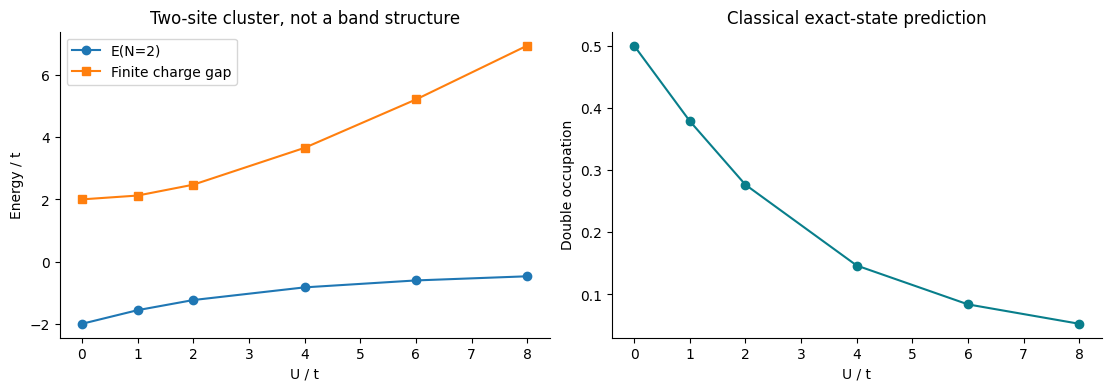

In [4]:
intermediate_tables(case)
plot_intermediate(case)

## 6. 实际运行与最终效果

模拟器使用固定种子逐次采样，counts 总数必须等于 shots。估计标准误由实际样本方差计算；近似 95% 区间可写作 estimate ± 1.96 × SE，但小样本及零计数需另用适当区间。本例不把这些区间当成硬件精度验收。

experiment,qubits,gates,shots,seed
occupation,4,41,1024,20261023


observable,estimate,standard_error,ideal_reference
occupation,0.171875,0.011795504,0.14644661


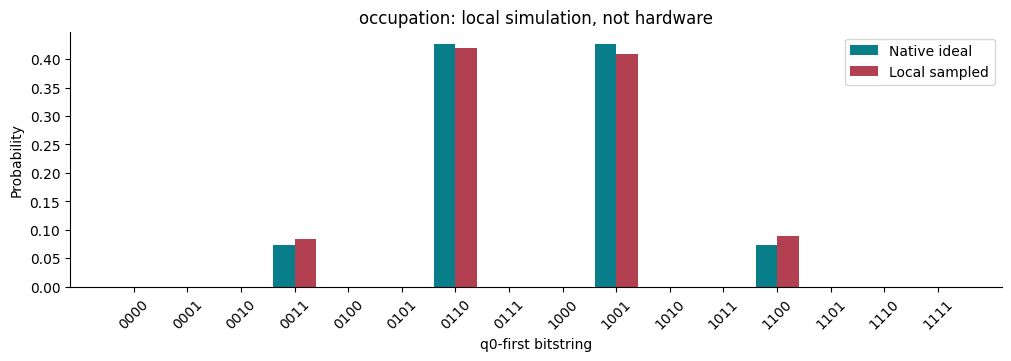

experiment,counts
occupation,"{""0110"": 430, ""1001"": 418, ""1100"": 91, ""0011"": 85}"


In [5]:
evidence = run_local_case(case, shots=SHOTS, seed=SEED)
show_measurements(case, evidence)

## 7. 可检查的电路输出

导出全部业务电路的 OpenQASM 2，位串采用 q0-first。可导出不等于已通过夸父设备门集、耦合图、深度和精度验收；本批不会访问凭据、提交任务或消耗金融额度。纯经典案例没有伪造量子电路。

In [6]:
for name, result in evidence['experiments'].items():
    print('\n---', name, '---\n'+result['openqasm2'])
if not evidence['experiments']:
    print('Classical cryptography / security workflow: no quantum circuit.')


--- occupation ---
OPENQASM 2.0;
include "qelib1.inc";
qreg q[4];
creg c[4];
ry(1.5707963267948968) q[0];
ry(1.5707963267948966) q[1];
cx q[0],q[1];
ry(0.78539816339744828) q[1];
cx q[0],q[1];
ry(1.5707963267948966) q[2];
cx q[0],q[2];
ry(1.5707963267948966) q[2];
cx q[0],q[2];
ry(-0.39269908169872414) q[3];
cx q[2],q[3];
ry(0.39269908169872414) q[3];
cx q[2],q[3];
cx q[1],q[3];
ry(-1.1780972450961724) q[3];
cx q[1],q[3];
cx q[1],q[3];
cx q[2],q[3];
ry(-0.39269908169872414) q[3];
cx q[2],q[3];
cx q[1],q[3];
cx q[0],q[3];
ry(-1.1780972450961724) q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[2],q[3];
ry(-0.39269908169872414) q[3];
cx q[2],q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[1],q[3];
ry(1.1780972450961724) q[3];
cx q[1],q[3];
cx q[0],q[3];
cx q[0],q[3];
cx q[1],q[3];
cx q[2],q[3];
ry(1.9634954084936207) q[3];
cx q[2],q[3];
cx q[1],q[3];
cx q[0],q[3];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];
measure q[3] -> c[3];



## 8. 结果解释、复做与非目标

interaction_sweep 展示相互作用增强时双占据下降。occupation 的 ideal_reference 应匹配解析值；estimate 的偏差属于有限 shots 采样误差。

两站点有限簇示例，没有晶体几何、周期边界、真实半导体能带、电池或催化材料数据库；不能直接输出真实材料带隙。

练习：对已有电路将 shots 改为 2048，比较估计与标准误；如果是纯经典密码案例，比较密文/公钥大小和篡改检测结果。安全案例的私钥只在临时目录或内存中存在，不输出密钥。重新执行此 Notebook 仍然只运行本地代码。

In [7]:
repeat = run_local_case(case, shots=2048, seed=SEED+100)
show_json({'execution_mode':repeat['execution_mode'], 'estimates':repeat['estimates'], 'new_cloud_tasks':repeat['new_cloud_tasks']})
assert all(sum(row['counts'].values()) == 2048 for row in repeat['experiments'].values())
assert repeat['new_cloud_tasks'] == 0
assert repeat['hardware_access'] is False

In [8]:
artifact = {'inputs':case.inputs, 'intermediate':case.intermediate, 'reference':case.reference, 'evidence':evidence}
path = root/'output/jupyter-notebook/science/03_materials_evidence.json'
path.parent.mkdir(parents=True, exist_ok=True)
path.write_text(json.dumps(artifact, ensure_ascii=False, indent=2), encoding='utf-8')
print('Evidence:', path.name)

Evidence: 03_materials_evidence.json


## 9. 参考与责任边界

独立编写应用代码，未复制上游 SDK 实现或第三方教程代码；下列资料用于数学与接口背景。

- [Qiskit Nature 格点模型定义](https://qiskit-community.github.io/qiskit-nature/tutorials/10_lattice_models.html)

本案例不是生产支持证书，也不代表 Qiskit / PennyLane 全量替代已经完成。